# 02 · Web Scraping with `requests` & Beautiful Soup

**Module 14 – Working with Data & the Web** · Estimated time: 60 min

> Based on 📗 *Guide to Web Scraping*, updated: uses `html.parser`/`lxml`, CSS selectors via `select()`, polite scraping (headers, delays, robots.txt), and saving results to CSV.

### 🎯 What you will learn
- How websites are built: HTML, CSS classes/IDs (📗)
- Rules and ethics of scraping (📗 + updated)
- `requests` + `BeautifulSoup`: page title, elements by tag/class, attributes
- CSS selectors with `select()` / `select_one()`
- Downloading images
- Scraping multiple pages (pagination) (📗 books.toscrape.com project)
- When to use an API or a headless browser instead

## 1. Basic components of a website (📗)

- **HTML** (*HyperText Markup Language*) gives the **structure**: tags like `<h1>`, `<p>`, `<a href="...">`, `<div class="...">`
- **CSS** (*Cascading Style Sheets*) gives the **style**, and its `class`/`id` names are exactly what we use to **locate** elements
- **JavaScript** adds interactivity; content created by JS isn't in the raw HTML (see section 8)

```html
<html>
  <head><title>Shop</title></head>
  <body>
    <h1 id="main-title">Books</h1>
    <div class="product">
      <h3><a href="/book/1" title="Python 101">Python 101</a></h3>
      <p class="price">£51.77</p>
      <p class="star-rating Three"></p>
    </div>
  </body>
</html>
```
- `id="main-title"` should be unique on a page → CSS selector `#main-title`
- `class="product"` can repeat → CSS selector `.product`

In your browser: right-click → **Inspect** to see the HTML behind any element.

## 2. Scraping guidelines (📗, updated)

- ✅ Prefer an **official API** if one exists (lesson 01)
- ✅ Check the site's **Terms of Service** and **`robots.txt`**
- ✅ Be polite: identify yourself (User-Agent), add **delays**, don't hammer servers
- ✅ Don't scrape personal data or paywalled/copyrighted content you aren't allowed to use
- ⚠️ Scrapers break when a site changes its HTML, so expect maintenance

The sites used here (`toscrape.com`, `example.com`) exist precisely for practising.

In [1]:
import urllib.robotparser
rp = urllib.robotparser.RobotFileParser("https://www.python.org/robots.txt")
rp.read()
print(rp.can_fetch("*", "https://www.python.org/about/"))

True


## 3. Setup

```bash
pip install requests beautifulsoup4 lxml
```
(📗 The bootcamp also shows `conda install`; pip works everywhere.)

In [2]:
import requests
from bs4 import BeautifulSoup
import time

HEADERS = {"User-Agent": "python-course-scraper (learning project)"}

## 4. Example task 0: grab the title of a page (📗)

In [3]:
res = requests.get("https://quotes.toscrape.com/", headers=HEADERS, timeout=10)
print(type(res), res.status_code)
print(res.text[:200])

<class 'requests.models.Response'> 200
<!DOCTYPE html>
<html lang="en">
<head>
	<meta charset="UTF-8">
	<title>Quotes to Scrape</title>
    <link rel="stylesheet" href="/static/bootstrap.min.css">
    <link rel="stylesheet" href="/static/m


In [4]:
soup = BeautifulSoup(res.text, "lxml")      # parser: "lxml" (fast) or "html.parser" (built in)
print(soup.title)                           # the <title> tag
print(soup.title.get_text(strip=True))
print(soup.select("title")[0].get_text(strip=True))   # same, via a CSS selector
print(soup.find("h1").get_text(strip=True))
print(soup.select_one("li.next a")["href"]) # attributes work like dict keys

<title>Quotes to Scrape</title>
Quotes to Scrape
Quotes to Scrape
Quotes to Scrape
/page/2/


> ⚠️ **Updated from the bootcamp:** it scraped `example.com` and Wikipedia pages. `example.com` now asks not to be used for testing, and Wikipedia prefers its official API (https://api.wikimedia.org) over scraping. This lesson uses the practice sites `quotes.toscrape.com` and `books.toscrape.com`.

### Selecting elements: cheat-sheet (📗)

| Syntax | Matches |
|---|---|
| `soup.select("div")` | all `<div>` elements |
| `soup.select("#some_id")` | element with `id="some_id"` |
| `soup.select(".some_class")` | elements with `class="some_class"` |
| `soup.select("div span")` | any `<span>` inside a `<div>` (descendant) |
| `soup.select("div > span")` | `<span>` directly inside a `<div>` (child) |
| `soup.select('a[href^="http"]')` | `<a>` whose `href` starts with `http` |
| `soup.select_one(...)` | the first match only (or `None`) |
| `soup.find("tag", class_="x")` / `find_all(...)` | the older, method-based API |

## 5. Example task 1: grab all elements of a class (quotes.toscrape.com)

In [5]:
res = requests.get("https://quotes.toscrape.com/", headers=HEADERS, timeout=10)
soup = BeautifulSoup(res.text, "lxml")

authors = {a.get_text() for a in soup.select(".author")}
print("Authors on page 1:", authors)

quotes = [q.get_text() for q in soup.select(".text")]
print(len(quotes), "quotes; first:", quotes[0][:60], "...")

top_tags = [t.get_text() for t in soup.select(".tag-item .tag")]   # only the top-ten box on the right
print("Top tags:", top_tags)

Authors on page 1: {'Marilyn Monroe', 'Albert Einstein', 'André Gide', 'J.K. Rowling', 'Thomas A. Edison', 'Jane Austen', 'Steve Martin', 'Eleanor Roosevelt'}
10 quotes; first: “The world as we have created it is a process of our thinkin ...
Top tags: ['love', 'inspirational', 'life', 'humor', 'books', 'reading', 'friendship', 'friends', 'truth', 'simile']


### Working with each item's structure

In [6]:
records = []
for quote_block in soup.select("div.quote"):
    records.append({
        "text": quote_block.select_one(".text").get_text(strip=True),
        "author": quote_block.select_one(".author").get_text(),
        "tags": [t.get_text() for t in quote_block.select(".tags a.tag")],
        "author_url": quote_block.select_one("a[href^='/author/']")["href"],
    })
print(records[0])

{'text': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”', 'author': 'Albert Einstein', 'tags': ['change', 'deep-thoughts', 'thinking', 'world'], 'author_url': '/author/Albert-Einstein'}


## 6. Example task 2: getting an image from a website (📗)

A Light in the Attic media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg


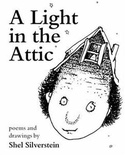

In [7]:
res = requests.get("https://books.toscrape.com/", headers=HEADERS, timeout=10)
soup = BeautifulSoup(res.text, "lxml")
img = soup.select_one("article.product_pod img")
print(img["alt"], img["src"])

from urllib.parse import urljoin
img_url = urljoin("https://books.toscrape.com/", img["src"])      # relative → absolute URL
image = requests.get(img_url, headers=HEADERS, timeout=10)
with open("book_cover.jpg", "wb") as f:        # binary mode for images
    f.write(image.content)

from IPython.display import Image as ShowImage
ShowImage("book_cover.jpg")

## 7. Example project: multiple pages and items (📗 books.toscrape.com)

**Goal:** find the titles of every book with a **2-star rating**.

Each book's rating is a CSS class, e.g. `<p class="star-rating Two">`.

In [8]:
base_url = "https://books.toscrape.com/catalogue/page-{}.html"
res = requests.get(base_url.format(1), headers=HEADERS, timeout=10)
soup = BeautifulSoup(res.text, "lxml")
products = soup.select(".product_pod")
print(len(products), "books on a page")
example = products[0]
print(example.select_one(".star-rating")["class"])     # ['star-rating', 'Three']
print(example.select_one("h3 a")["title"])              # the full title is in the title attribute

20 books on a page
['star-rating', 'Three']
A Light in the Attic


In [9]:
two_star_titles = []
for n in range(1, 6):                       # first 5 of the 50 pages (be polite: delay between requests)
    soup = BeautifulSoup(requests.get(base_url.format(n), headers=HEADERS, timeout=10).text, "lxml")
    for book in soup.select(".product_pod"):
        if "Two" in book.select_one(".star-rating")["class"]:
            two_star_titles.append(book.select_one("h3 a")["title"])
    time.sleep(0.5)
print(len(two_star_titles), "two-star books found, e.g.:")
print(*two_star_titles[:5], sep="\n")

19 two-star books found, e.g.:
Starving Hearts (Triangular Trade Trilogy, #1)
Libertarianism for Beginners
It's Only the Himalayas
How Music Works
Maude (1883-1993):She Grew Up with the country


### Pagination without knowing the number of pages (📗 exercise solution #2, improved)

Follow the **"next"** link until there isn't one:

In [10]:
url = "https://quotes.toscrape.com/"
all_authors = set()
pages = 0
while url:
    soup = BeautifulSoup(requests.get(url, headers=HEADERS, timeout=10).text, "lxml")
    all_authors.update(a.get_text() for a in soup.select(".author"))
    next_link = soup.select_one("li.next > a")
    url = urljoin(url, next_link["href"]) if next_link else None
    pages += 1
    time.sleep(0.3)
print(f"{pages} pages, {len(all_authors)} unique authors")

10 pages, 50 unique authors


## 8. Saving the results

In [11]:
import csv
with open("quotes.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["text", "author", "tags", "author_url"])
    writer.writeheader()
    for r in records:
        writer.writerow({**r, "tags": ";".join(r["tags"])})
print(open("quotes.csv", encoding="utf-8").read()[:250])

text,author,tags,author_url
“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”,Albert Einstein,change;deep-thoughts;thinking;world,/author/Albert-Einstein
"“It is our choices, Harry, th


## 9. When BeautifulSoup isn't enough

- **JavaScript-rendered pages**: the HTML you download is nearly empty because content is loaded by JS. Options: find the JSON API the page calls (browser DevTools → *Network* tab, often the best!), or drive a real browser with **Playwright** or **Selenium**.
- **Large crawls**: use **Scrapy** (a full scraping framework with scheduling, retries and pipelines).

In [12]:
res = requests.get("https://quotes.toscrape.com/js/", headers=HEADERS, timeout=10)
print("Quotes in raw HTML of the JS version:", len(BeautifulSoup(res.text, "lxml").select(".quote")))   # 0!

Quotes in raw HTML of the JS version: 0


## 📝 Summary
- `requests.get(url, headers=..., timeout=...)` → `BeautifulSoup(res.text, "lxml")`.
- `select()` / `select_one()` with CSS selectors; `.get_text()`, `["attr"]`.
- Download binary content with `res.content` and `"wb"`.
- Paginate by following "next" links; add delays; save to CSV/JSON.
- Prefer APIs; use Playwright/Selenium for JS-heavy sites.

## 🏋️ Practice (📗 Web Scraping Exercises, full version in `exercises/`)
1. Get the names of all the authors on the first page of quotes.toscrape.com.
2. Create a list of all the quotes on the first page.
3. Extract the top ten tags (right-hand box) from the home page.
4. Loop through all the pages and get all unique authors (without knowing the page count).
5. On books.toscrape.com, compute the **average price** of the books on page 1.

<details><summary>Show solution for 5</summary>

```python
import requests
from bs4 import BeautifulSoup
# .content (bytes) lets BeautifulSoup detect the UTF-8 encoding, so "£" isn't garbled into "Â£"
soup = BeautifulSoup(requests.get("https://books.toscrape.com/", timeout=10).content, "lxml")
prices = [float(p.get_text().replace("£", "")) for p in soup.select(".price_color")]
print(round(sum(prices) / len(prices), 2))
```
</details>